In [1]:
from pathlib import Path
import pandas as pd

# Locate the Downloads folder
downloads = Path.home() / "Downloads"

# Load the cleaned datasets
sales = pd.read_csv(
    downloads / "sales_cleaned.csv",
    parse_dates=["transaction_date"]
)

products = pd.read_csv(downloads / "products_cleaned.csv")
stores = pd.read_csv(downloads / "stores_cleaned.csv")
customers = pd.read_csv(downloads / "customers_cleaned.csv")
promotions = pd.read_csv(downloads / "promotions_cleaned.csv")
calendar = pd.read_csv(
    downloads / "calendar_cleaned.csv",
    parse_dates=["date"]
)

# Check that everything loaded correctly
print("Sales:", sales.shape)
print("Products:", products.shape)
print("Stores:", stores.shape)
print("Customers:", customers.shape)
print("Promotions:", promotions.shape)
print("Calendar:", calendar.shape)

print("\nSales columns:")
print(sales.columns.tolist())

Sales: (555729, 11)
Products: (100, 5)
Stores: (8, 5)
Customers: (6000, 5)
Promotions: (13901, 6)
Calendar: (731, 9)

Sales columns:
['transaction_id', 'transaction_date', 'store_id', 'product_id', 'customer_id', 'quantity', 'unit_price_kes', 'discount_rate', 'selling_price_kes', 'payment_method', 'promotion_id']


In [4]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Locate Downloads
downloads = Path.home() / "Downloads"

# Load the cleaned sales data
sales = pd.read_csv(
    downloads / "sales_validated.csv",
    parse_dates=["transaction_date"]
)

# Inspect the data
print("Dataset shape:", sales.shape)
print("\nColumn names:")
print(sales.columns.tolist())

print("\nFirst five rows:")
display(sales.head())

print("\nMissing values:")
display(sales.isnull().sum())

Dataset shape: (555731, 11)

Column names:
['transaction_id', 'transaction_date', 'store_id', 'product_id', 'customer_id', 'quantity', 'unit_price_kes', 'discount_rate', 'selling_price_kes', 'payment_method', 'promotion_id']

First five rows:


,transaction_id,transaction_date,store_id,product_id,customer_id,quantity,unit_price_kes,discount_rate,selling_price_kes,payment_method,promotion_id
0,TXN000000001,2024-01-01,STR001,PRD001,CUS01228,6,172.99,0.0,172.99,Cash,NaN
1,TXN000000002,2024-01-01,STR001,PRD002,NaN,18,316.87,0.0,316.87,M-Pesa,NaN
2,TXN000000003,2024-01-01,STR001,PRD003,CUS05025,4,178.87,0.0,178.87,M-Pesa,NaN
3,TXN000000004,2024-01-01,STR001,PRD004,CUS01223,5,343.59,0.0,343.59,M-Pesa,NaN
4,TXN000000005,2024-01-01,STR001,PRD005,NaN,8,305.40,0.0,305.40,Cash,NaN



Missing values:


transaction_id            0
transaction_date          0
store_id                  0
product_id                0
customer_id           49783
quantity                  0
unit_price_kes            0
discount_rate             0
selling_price_kes         0
payment_method            0
promotion_id         541832
dtype: int64

## Calculating Revenue

In [5]:
# Calculate total revenue for each sales row
sales["total_revenue_kes"] = (
    sales["quantity"] * sales["selling_price_kes"]
)

# Calculate total revenue by product
product_revenue = (
    sales.groupby("product_id")["total_revenue_kes"]
    .sum()
    .sort_values(ascending=False)
)

# Display the top 10 products
top_10_products = product_revenue.head(10)

display(
    top_10_products.reset_index()
    .rename(columns={"total_revenue_kes": "total_revenue_kes"})
)

,product_id,total_revenue_kes
0,PRD059,27573360.08
1,PRD004,27281550.73
2,PRD018,23930220.64
3,PRD002,23503059.65
4,PRD005,22703034.77
5,PRD012,19822695.15
6,PRD046,19814732.39
7,PRD031,19290861.09
8,PRD015,18419761.11
9,PRD052,13953062.55


## Top 10 Products by Total Sales Revenue"

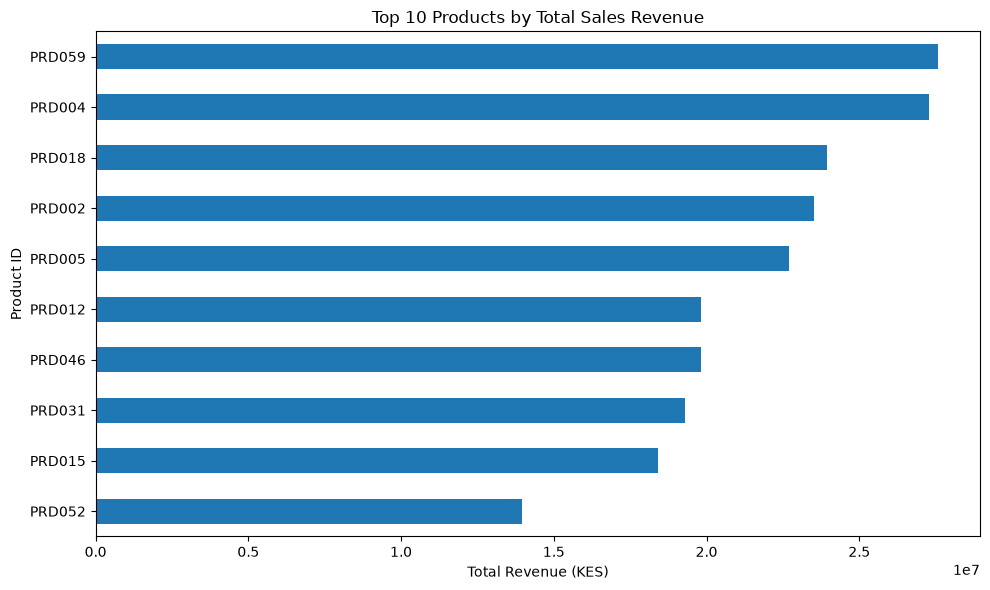

In [6]:
import matplotlib.pyplot as plt

top_10_products.sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Top 10 Products by Total Sales Revenue")
plt.xlabel("Total Revenue (KES)")
plt.ylabel("Product ID")
plt.tight_layout()
plt.show()

## Calculate revenue by product category

In [8]:
# Join sales with product information
sales_products = sales.merge(
    products[["product_id", "product_name", "category"]],
    on="product_id",
    how="left",
    validate="many_to_one"
)

# Calculate total revenue by category
category_revenue = (
    sales_products
    .groupby("category")["total_revenue_kes"]
    .sum()
    .sort_values(ascending=False)
)

# Display results
display(
    category_revenue
    .reset_index()
    .rename(columns={"total_revenue_kes": "total_revenue_kes"})
)

,category,total_revenue_kes
0,Staples,2.545724e+08
1,Dairy & Eggs,1.978414e+08
2,Fresh Produce,1.469171e+08
3,Personal Care,1.026901e+08
4,Household,7.183946e+07


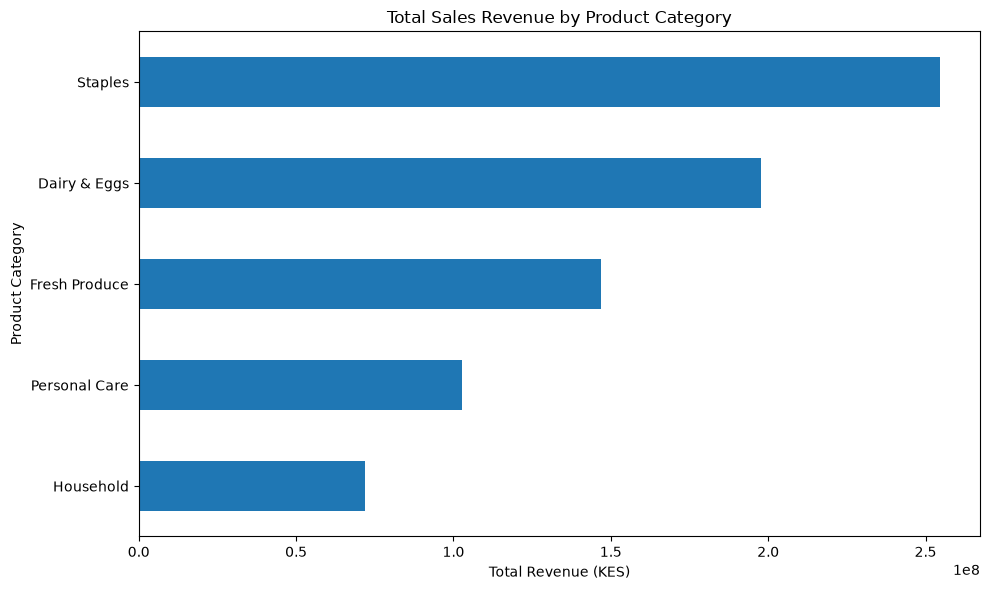

In [9]:
category_revenue.sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Total Sales Revenue by Product Category")
plt.xlabel("Total Revenue (KES)")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

In [10]:
print("stores exists:", "stores" in globals())

if "stores" in globals():
    print(stores.columns.tolist())
    display(stores.head())

stores exists: True
['store_id', 'store_name', 'county', 'location_type', 'opening_date']


,store_id,store_name,county,location_type,opening_date
0,STR001,Nairobi Central,Nairobi,Urban,2023-01-01
1,STR002,Westlands Market,Nairobi,Urban,2023-01-01
2,STR003,Thika Town,Kiambu,Urban,2023-01-01
3,STR004,Kiambu Road,Kiambu,Peri-urban,2023-01-01
4,STR005,Nakuru Town,Nakuru,Urban,2023-01-01


## Calculating store performance

In [11]:
# Summarize sales performance by store
store_performance = (
    sales.groupby("store_id")
    .agg(
        total_revenue_kes=("total_revenue_kes", "sum"),
        total_units_sold=("quantity", "sum"),
        number_of_sales=("transaction_id", "count")
    )
    .reset_index()
)

# Add store names and locations
store_performance = store_performance.merge(
    stores[["store_id", "store_name", "county", "location_type"]],
    on="store_id",
    how="left",
    validate="one_to_one"
)

# Rank stores by revenue
store_performance = store_performance.sort_values(
    "total_revenue_kes",
    ascending=False
)

display(store_performance)

,store_id,total_revenue_kes,total_units_sold,number_of_sales,store_name,county,location_type
0,STR001,1.274357e+08,746263,70920,Nairobi Central,Nairobi,Urban
1,STR002,1.169374e+08,686274,70530,Westlands Market,Nairobi,Urban
6,STR007,1.046868e+08,626267,69999,Mombasa Coast,Mombasa,Urban
2,STR003,9.351750e+07,565156,69448,Thika Town,Kiambu,Urban
4,STR005,8.820603e+07,536703,69133,Nakuru Town,Nakuru,Urban
7,STR008,8.571002e+07,526852,69119,Kisumu Lakeside,Kisumu,Urban
3,STR004,8.386050e+07,505952,68751,Kiambu Road,Kiambu,Peri-urban
5,STR006,7.350656e+07,448538,67831,Naivasha Fresh,Nakuru,Peri-urban


## Calculating revenue by store

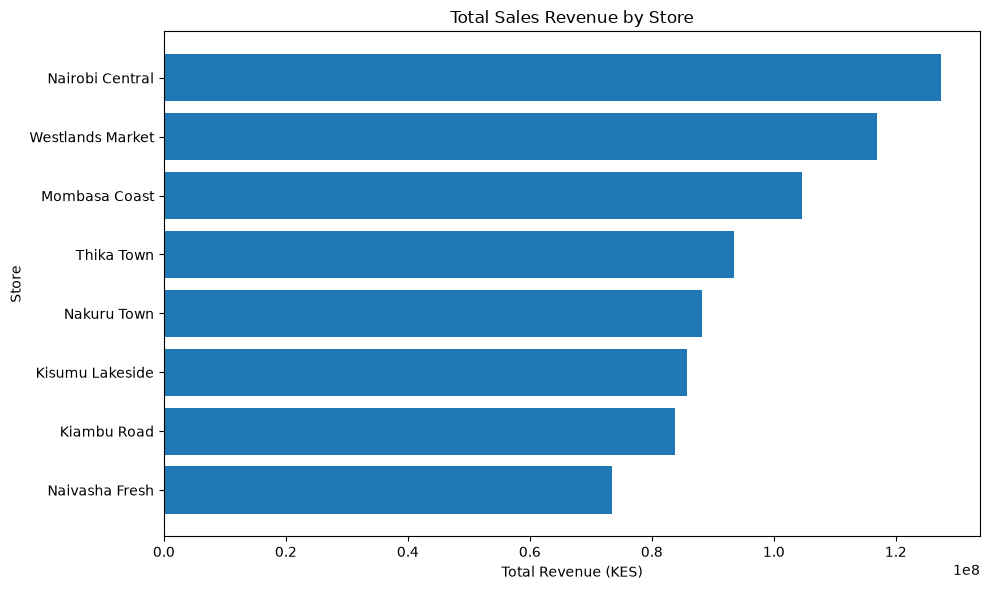

In [12]:
import matplotlib.pyplot as plt

store_chart = store_performance.sort_values("total_revenue_kes")

plt.figure(figsize=(10, 6))
plt.barh(
    store_chart["store_name"],
    store_chart["total_revenue_kes"]
)

plt.title("Total Sales Revenue by Store")
plt.xlabel("Total Revenue (KES)")
plt.ylabel("Store")
plt.tight_layout()
plt.show()

In [13]:
county_performance = (
    store_performance.groupby("county")
    .agg(
        total_revenue_kes=("total_revenue_kes", "sum"),
        total_units_sold=("total_units_sold", "sum"),
        number_of_stores=("store_id", "nunique")
    )
    .sort_values("total_revenue_kes", ascending=False)
    .reset_index()
)

display(county_performance)

,county,total_revenue_kes,total_units_sold,number_of_stores
0,Nairobi,2.443730e+08,1432537,2
1,Kiambu,1.773780e+08,1071108,2
2,Nakuru,1.617126e+08,985241,2
3,Mombasa,1.046868e+08,626267,1
4,Kisumu,8.571002e+07,526852,1


## Comparing revenue across counties

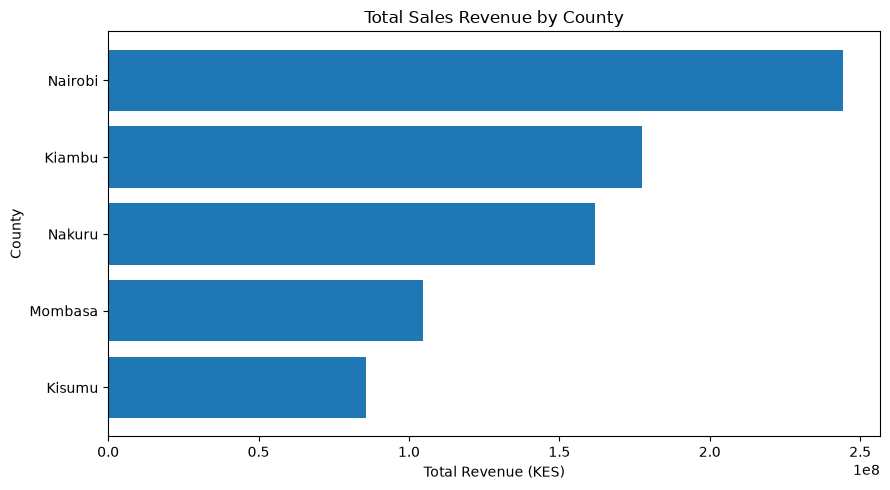

In [14]:
county_chart = county_performance.sort_values("total_revenue_kes")

plt.figure(figsize=(9, 5))
plt.barh(
    county_chart["county"],
    county_chart["total_revenue_kes"]
)

plt.title("Total Sales Revenue by County")
plt.xlabel("Total Revenue (KES)")
plt.ylabel("County")
plt.tight_layout()
plt.show()

## Comparing sales with and without discounts

In [16]:

# Group sales by discount status
sales["discount_status"] = sales["discount_rate"].apply(
    lambda x: "Discounted" if x > 0 else "No discount"
)

discount_comparison = (
    sales.groupby("discount_status")
    .agg(
        total_revenue_kes=("total_revenue_kes", "sum"),
        total_units_sold=("quantity", "sum"),
        number_of_sales=("transaction_id", "count"),
        average_discount_rate=("discount_rate", "mean")
    )
    .reset_index()
)

display(discount_comparison)


,discount_status,total_revenue_kes,total_units_sold,number_of_sales,average_discount_rate
0,Discounted,1.991981e+07,137815,13899,0.125491
1,No discount,7.539406e+08,4504190,541832,0.000000


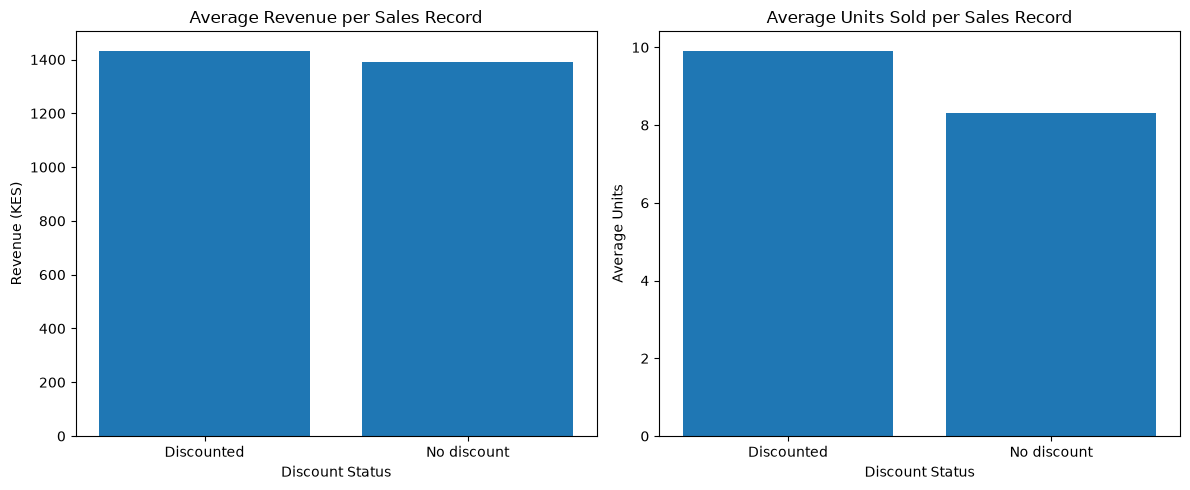

,discount_status,average_revenue_per_sale,average_units_per_sale
0,Discounted,1433.18,9.92
1,No discount,1391.47,8.31


In [17]:

# Calculate average performance by discount status
discount_average = (
    sales.groupby("discount_status")
    .agg(
        average_revenue_per_sale=("total_revenue_kes", "mean"),
        average_units_per_sale=("quantity", "mean")
    )
    .reset_index()
)

# Create two comparison charts
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Average revenue per sales record
axes[0].bar(
    discount_average["discount_status"],
    discount_average["average_revenue_per_sale"]
)
axes[0].set_title("Average Revenue per Sales Record")
axes[0].set_ylabel("Revenue (KES)")
axes[0].set_xlabel("Discount Status")

# Average units sold per sales record
axes[1].bar(
    discount_average["discount_status"],
    discount_average["average_units_per_sale"]
)
axes[1].set_title("Average Units Sold per Sales Record")
axes[1].set_ylabel("Average Units")
axes[1].set_xlabel("Discount Status")

plt.tight_layout()
plt.show()

display(discount_average.round(2))


In [18]:

# Keep sales records with an identified customer
customer_sales = sales.dropna(subset=["customer_id"]).copy()

# Summarize purchasing activity by customer
customer_summary = (
    customer_sales.groupby("customer_id")
    .agg(
        total_revenue_kes=("total_revenue_kes", "sum"),
        total_units_purchased=("quantity", "sum"),
        number_of_purchases=("transaction_id", "count")
    )
    .reset_index()
)

print("Identified customers:", customer_summary["customer_id"].nunique())
print("Customer summary shape:", customer_summary.shape)

display(
    customer_summary.sort_values(
        "total_revenue_kes", ascending=False
    ).head(10)
)


Identified customers: 6000
Customer summary shape: (6000, 4)


,customer_id,total_revenue_kes,total_units_purchased,number_of_purchases
5633,CUS05634,212298.88,1101,149
3626,CUS03627,212138.04,1155,144
732,CUS00733,206212.05,1220,146
840,CUS00841,201054.72,1048,132
2007,CUS02008,194432.82,1105,130
3917,CUS03918,192987.75,1116,137
737,CUS00738,192720.62,1050,130
599,CUS00600,192315.04,1052,127
829,CUS00830,190671.31,1050,136
4509,CUS04510,189426.81,1114,136


## Customer purchasing frequency

count    6000.000000
mean       84.324667
std        22.509199
min        39.000000
25%        65.000000
50%        82.000000
75%       100.000000
max       154.000000
Name: number_of_purchases, dtype: float64


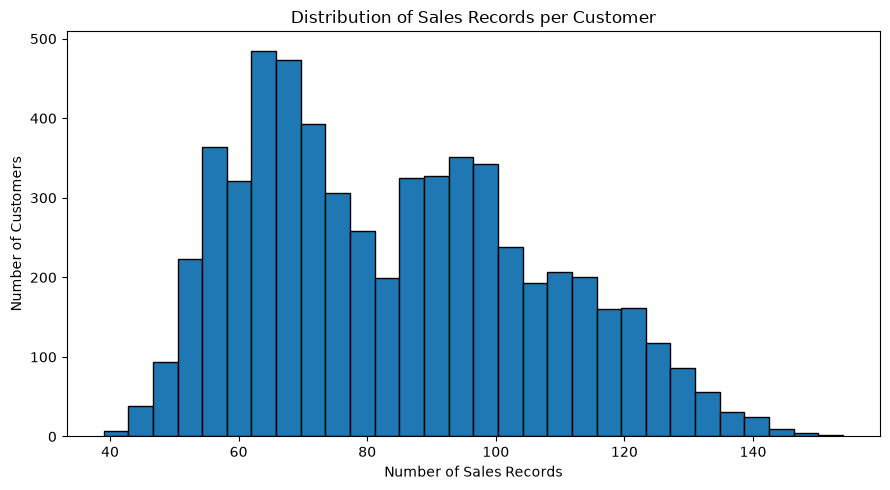

In [19]:

# Summarize the distribution of customer purchase frequency
print(
    customer_summary["number_of_purchases"].describe()
)

# Plot the distribution of purchases per customer
plt.figure(figsize=(9, 5))
plt.hist(
    customer_summary["number_of_purchases"],
    bins=30,
    edgecolor="black"
)
plt.title("Distribution of Sales Records per Customer")
plt.xlabel("Number of Sales Records")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()


,number_of_purchases,total_revenue_kes
number_of_purchases,1.000,0.696
total_revenue_kes,0.696,1.000


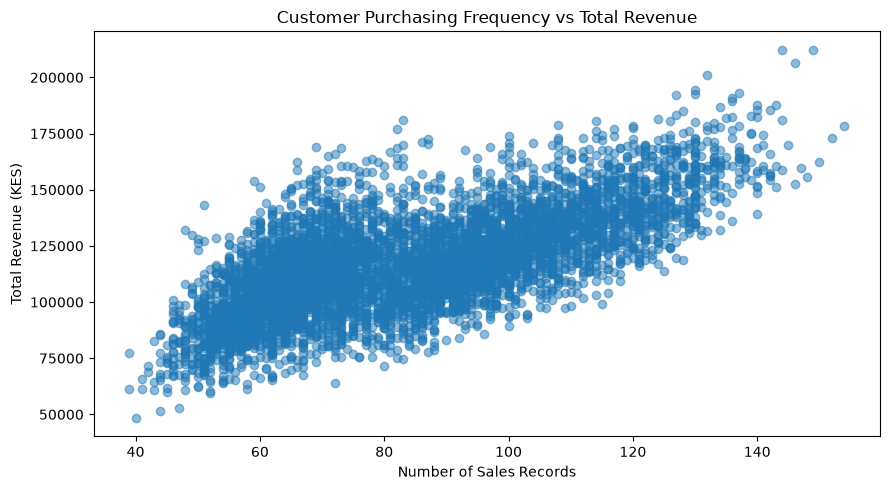

In [20]:

# Calculate the relationship between purchasing frequency and revenue
customer_correlation = customer_summary[
    ["number_of_purchases", "total_revenue_kes"]
].corr()

display(customer_correlation.round(3))

# Visualize the relationship
plt.figure(figsize=(9, 5))
plt.scatter(
    customer_summary["number_of_purchases"],
    customer_summary["total_revenue_kes"],
    alpha=0.5
)
plt.title("Customer Purchasing Frequency vs Total Revenue")
plt.xlabel("Number of Sales Records")
plt.ylabel("Total Revenue (KES)")
plt.tight_layout()
plt.show()


In [21]:

from pathlib import Path
import pandas as pd

downloads = Path.home() / "Downloads"

daily_demand = pd.read_csv(
    downloads / "daily_demand.csv",
    parse_dates=["transaction_date"]
)

demand_features = pd.read_csv(
    downloads / "demand_features.csv",
    parse_dates=["transaction_date"]
)

print("Daily demand shape:", daily_demand.shape)
print("Daily demand columns:", daily_demand.columns.tolist())
display(daily_demand.head())

print("\nDemand features shape:", demand_features.shape)
print("Demand features columns:", demand_features.columns.tolist())
display(demand_features.head())


Daily demand shape: (555729, 5)
Daily demand columns: ['transaction_date', 'store_id', 'product_id', 'daily_quantity', 'transactions']


,transaction_date,store_id,product_id,daily_quantity,transactions
0,2024-01-01,STR001,PRD001,6,1
1,2024-01-02,STR001,PRD001,5,1
2,2024-01-03,STR001,PRD001,5,1
3,2024-01-04,STR001,PRD001,6,1
4,2024-01-05,STR001,PRD001,9,1



Demand features shape: (555729, 13)
Demand features columns: ['transaction_date', 'store_id', 'product_id', 'daily_quantity', 'transactions', 'day_of_week', 'day_name', 'month', 'year', 'day_of_month', 'is_weekend', 'is_public_holiday_simulated', 'holiday_name_simulated']


,transaction_date,store_id,product_id,daily_quantity,transactions,day_of_week,day_name,month,year,day_of_month,is_weekend,is_public_holiday_simulated,holiday_name_simulated
0,2024-01-01,STR001,PRD001,6,1,0,Monday,1,2024,1,0,True,New Year's Day
1,2024-01-02,STR001,PRD001,5,1,1,Tuesday,1,2024,2,0,False,NaN
2,2024-01-03,STR001,PRD001,5,1,2,Wednesday,1,2024,3,0,False,NaN
3,2024-01-04,STR001,PRD001,6,1,3,Thursday,1,2024,4,0,False,NaN
4,2024-01-05,STR001,PRD001,9,1,4,Friday,1,2024,5,0,False,NaN


## daily demand over time

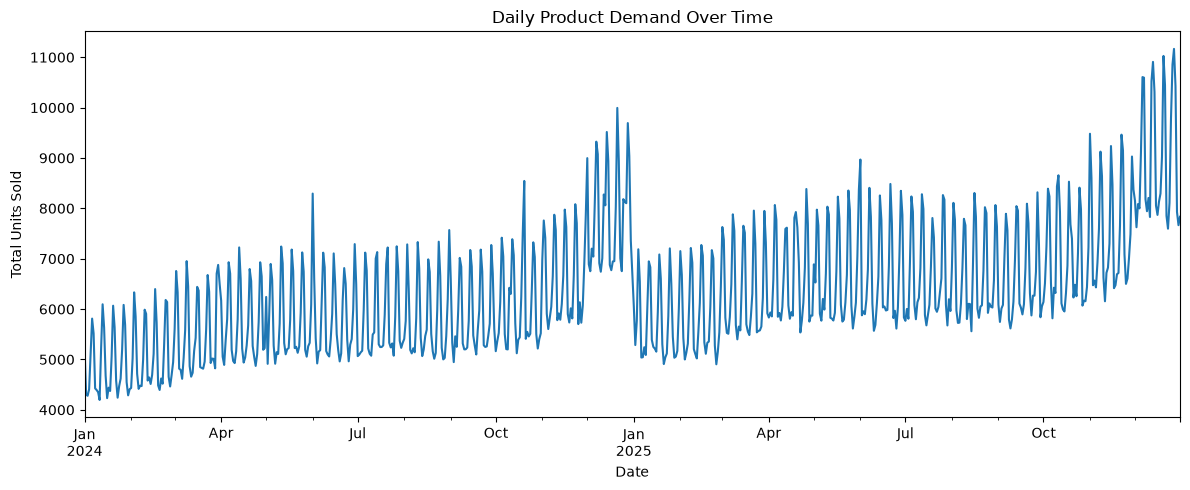

In [22]:

import matplotlib.pyplot as plt

# Total daily demand across all stores and products
daily_trend = (
    demand_features.groupby("transaction_date")["daily_quantity"]
    .sum()
)

plt.figure(figsize=(12, 5))
daily_trend.plot()
plt.title("Daily Product Demand Over Time")
plt.xlabel("Date")
plt.ylabel("Total Units Sold")
plt.tight_layout()
plt.show()


## Average demand by day of the week

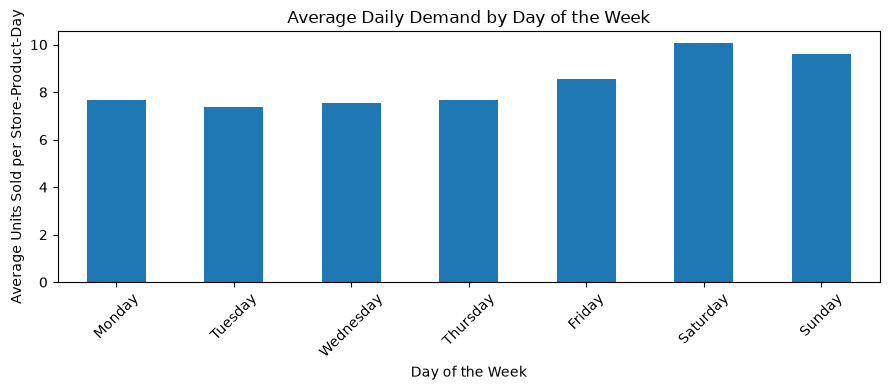

In [23]:

weekday_demand = demand_features.groupby(
    "day_name"
)["daily_quantity"].mean()

weekday_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

weekday_demand = weekday_demand.reindex(weekday_order)

weekday_demand.plot(kind="bar", figsize=(9, 4))
plt.title("Average Daily Demand by Day of the Week")
plt.xlabel("Day of the Week")
plt.ylabel("Average Units Sold per Store-Product-Day")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## Monthly demand trend

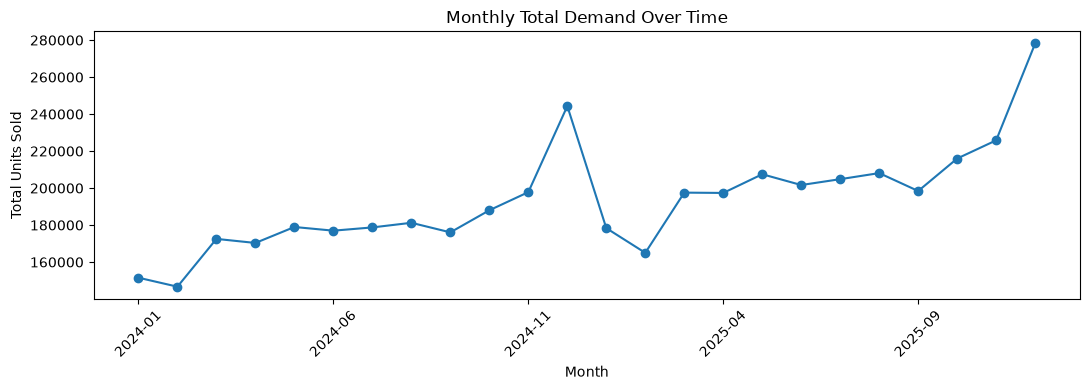

In [24]:

monthly_demand = (
    demand_features.groupby(
        demand_features["transaction_date"].dt.to_period("M")
    )["daily_quantity"]
    .sum()
)

monthly_demand.index = monthly_demand.index.astype(str)

monthly_demand.plot(kind="line", marker="o", figsize=(11, 4))
plt.title("Monthly Total Demand Over Time")
plt.xlabel("Month")
plt.ylabel("Total Units Sold")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## Actual vs. baseline forecast

Baseline MAE: 618.27 units per day


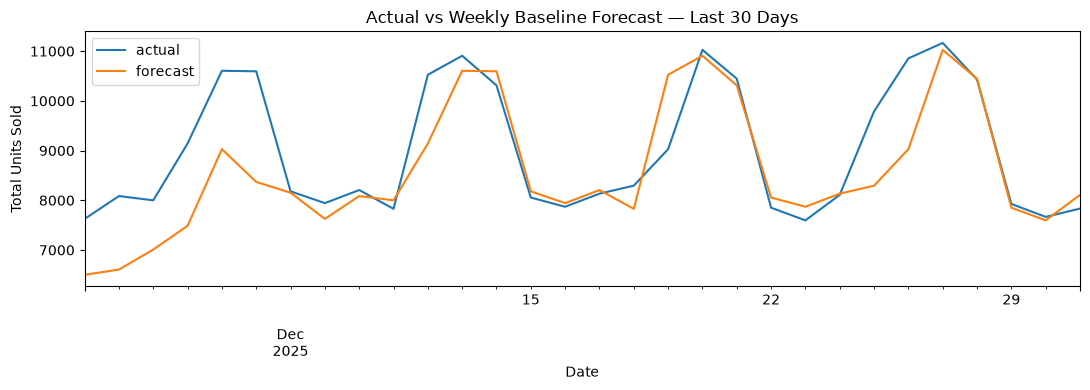

In [25]:

from sklearn.metrics import mean_absolute_error
import numpy as np

# Total units sold each day
daily_total = (
    demand_features.groupby("transaction_date")["daily_quantity"]
    .sum()
    .sort_index()
)

# Predict demand using the same weekday from the previous week
results = pd.DataFrame({"actual": daily_total})
results["forecast"] = results["actual"].shift(7)

# Evaluate the last 30 days
test = results.iloc[-30:].dropna()

mae = mean_absolute_error(test["actual"], test["forecast"])
print(f"Baseline MAE: {mae:.2f} units per day")

test.plot(figsize=(11, 4))
plt.title("Actual vs Weekly Baseline Forecast — Last 30 Days")
plt.xlabel("Date")
plt.ylabel("Total Units Sold")
plt.tight_layout()
plt.show()


## Five Key EDA Findings

1. **Product and Category Performance:** Staples generated the highest category revenue at approximately KES 255 million, while Household products generated the lowest at approximately KES 72 million.

2. **Store Performance:** Nairobi Central was the highest-revenue individual store, generating approximately KES 127 million. Nairobi County had the highest combined revenue across its two stores.

3. **Promotions and Discounts:** Discounted sales records had slightly higher average revenue (KES 1,433.18) and average units sold (9.92) than non-discounted records. However, this association does not prove that discounts caused higher sales.

4. **Customer Purchasing Patterns:** Customer purchase frequency was positively associated with total revenue, with a correlation of 0.696. Customers who purchased more frequently generally accumulated higher total revenue.

5. **Demand Trends and Seasonality:** Demand was generally higher in 2025 than in 2024, peaked in December in both years, and was higher on weekends, particularly Saturdays. These patterns may help inform inventory planning and demand forecasting.